# 4. Makine Öğrenmesi Modellerinin Eğitimi ve Karşılaştırılması

Bu bölümde **NASA C-MAPSS (`FD001`)** veri seti için hazırlanmış `train_fe.csv`, `val_fe.csv`, `test_fe.csv` ve `selected_features.json` kullanılarak `RUL_capped125` hedefi üzerinde dört model eğitilir ve karşılaştırılır:

- **Sızıntısız Ayrım:** `val_fe.csv` içindeki motorlar (`unit`) eğitim verisinden çıkarılır; ölçekleme (`StandardScaler` + `RobustScaler`) yalnızca eğitim verisine (`X_tr`) uygulanır.
- **Ezberleme Kontrolü:** Her model için `Train`, `Validation` ve `Test (Son Döngü)` metrikleri birlikte yazdırılır; ağaç/boosting modellerinde derinlik ve alt örnekleme sınırları ile ezberleme (`overfitting`) engellenir.
- **Tüm Döngülerde Doğruluk (%):** `0–125` döngü ölçeğine göre `(1 - MAE / 125) * 100` formülüyle genel yüzde doğruluk ve `R² (%)` gösterilir.

## 4.1 Linear Regression (Baseline)

Doğrusal ilişkileri modelleyen temel başlangıç (`baseline`) modelidir. Diğer modellerin test performansı üzerine ne kadar katkı sağladığını görmek için referans noktası oluşturur.

Linear Regression (Baseline) eğitiliyor...
--- Linear Regression Sonuçları ---
Train      -> RMSE: 21.03 | MAE: 17.21 | Doğruluk: %86.23
Test (Son) -> RMSE: 20.43 | MAE: 16.24 | R2: %74.00 | Doğruluk: %87.00
Validation -> RMSE: 19.78 | MAE: 15.96 | R2: %77.51 | Doğruluk: %87.23
Ezberleme  -> Test - Train RMSE: -0.59 döngü (Dengeli (Ezberleme yok))


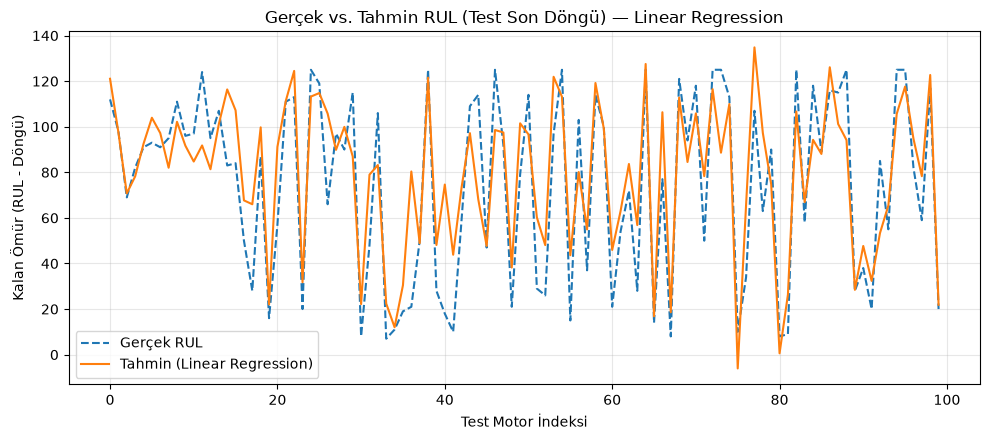

In [2]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler

TARGET_COL = "RUL_capped125"
RUL_CAP = 125.0

# 1) Verileri ve seçili özellikleri yükle
base_dir = Path.cwd()
project_root = (
    base_dir.parent
    if base_dir.name == "notebooks" and (base_dir.parent / "artifacts").exists()
    else base_dir
)
artifacts_dir = project_root / "artifacts"

train_fe = pd.read_csv(artifacts_dir / "train_fe.csv")
val_fe = pd.read_csv(artifacts_dir / "val_fe.csv")
test_fe = pd.read_csv(artifacts_dir / "test_fe.csv")

with open(
    artifacts_dir / "selected_features.json", "r", encoding="utf-8"
) as f:
  selected_features = json.load(f)["selected_features"]

# 2) Motor (unit) bazlı sızıntısız eğitim / validation ayrımı
val_units = set(val_fe["unit"].unique())
train_only_df = train_fe[~train_fe["unit"].isin(val_units)].copy()
assert set(train_only_df["unit"]).isdisjoint(
    val_units
), "Veri sızıntısı: Train ve Val arasında ortak motor var!"

X_tr = train_only_df[selected_features]
y_tr = train_only_df[TARGET_COL]

X_val = val_fe[selected_features]
y_val = val_fe[TARGET_COL]

# 3) Test son döngü (last cycle) verisi
data_dir = next(
    (
        p
        for p in [project_root / "data", Path("data"), Path("../data")]
        if (p / "RUL_FD001.txt").exists()
    ),
    None,
)
assert data_dir is not None, "RUL_FD001.txt bulunamadı! data/ klasörünü kontrol et."

test_last = test_fe.sort_values("cycle").groupby("unit", as_index=False).last()
X_test_last = test_last[selected_features]
y_true_raw = pd.read_csv(
    data_dir / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"]
)["RUL"]
y_test_true = np.minimum(y_true_raw.values, RUL_CAP)

# 4) Ölçekleyici (yalnızca X_tr üzerinde fit edilir)
robust_cols = [
    c for c in selected_features if c.endswith("_diff") or "_roll_std_" in c
]
standard_cols = [c for c in selected_features if c not in robust_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("std", StandardScaler(), standard_cols),
        ("rob", RobustScaler(), robust_cols),
    ],
    remainder="drop",
)

results_summary = []


def evaluate_model(model, model_name):
  model.fit(X_tr, y_tr)

  # Train (Ezberleme kontrolü)
  tr_pred = model.predict(X_tr)
  tr_rmse = float(np.sqrt(mean_squared_error(y_tr, tr_pred)))
  tr_mae = float(mean_absolute_error(y_tr, tr_pred))
  tr_acc = max(0.0, (1.0 - tr_mae / RUL_CAP) * 100.0)

  # Test Son Döngü (Ana karşılaştırma)
  test_pred = model.predict(X_test_last)
  test_rmse = float(np.sqrt(mean_squared_error(y_test_true, test_pred)))
  test_mae = float(mean_absolute_error(y_test_true, test_pred))
  test_r2 = float(r2_score(y_test_true, test_pred))
  test_acc = max(0.0, (1.0 - test_mae / RUL_CAP) * 100.0)

  # Validation (İyileştirme aşaması için referans)
  val_pred = model.predict(X_val)
  val_rmse = float(np.sqrt(mean_squared_error(y_val, val_pred)))
  val_mae = float(mean_absolute_error(y_val, val_pred))
  val_r2 = float(r2_score(y_val, val_pred))
  val_acc = max(0.0, (1.0 - val_mae / RUL_CAP) * 100.0)

  rmse_gap = test_rmse - tr_rmse
  if rmse_gap <= 4.0:
    overfit_durum = "Dengeli (Ezberleme yok)"
  elif rmse_gap <= 8.0:
    overfit_durum = "Hafif Fark (Kontrollü)"
  else:
    overfit_durum = "Ezberleme Riski Yüksek"

  print(f"--- {model_name} Sonuçları ---")
  print(
      f"Train      -> RMSE: {tr_rmse:.2f} | MAE: {tr_mae:.2f} | Doğruluk:"
      f" %{tr_acc:.2f}"
  )
  print(
      f"Test (Son) -> RMSE: {test_rmse:.2f} | MAE: {test_mae:.2f} | R2:"
      f" %{test_r2*100:.2f} | Doğruluk: %{test_acc:.2f}"
  )
  print(
      f"Validation -> RMSE: {val_rmse:.2f} | MAE: {val_mae:.2f} | R2:"
      f" %{val_r2*100:.2f} | Doğruluk: %{val_acc:.2f}"
  )
  print(
      f"Ezberleme  -> Test - Train RMSE: {rmse_gap:+.2f} döngü ({overfit_durum})"
  )

  row = {
      "Model": model_name,
      "Test RMSE": round(test_rmse, 2),
      "Test Doğruluk (%)": round(test_acc, 2),
      "Test R2 (%)": round(test_r2 * 100, 2),
      "Train RMSE": round(tr_rmse, 2),
      "Val RMSE": round(val_rmse, 2),
      "Val Doğruluk (%)": round(val_acc, 2),
      "Ezberleme": overfit_durum,
  }

  plt.figure(figsize=(10, 4.5))
  plt.plot(y_test_true, label="Gerçek RUL", linestyle="--")
  plt.plot(test_pred, label=f"Tahmin ({model_name})")
  plt.title(f"Gerçek vs. Tahmin RUL (Test Son Döngü) — {model_name}")
  plt.xlabel("Test Motor İndeksi")
  plt.ylabel("Kalan Ömür (RUL - Döngü)")
  plt.legend()
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.show()

  non_empty = [r for r in results_summary if r["Model"] != model_name]
  results_summary[:] = non_empty + [row]
  return test_pred


lr_model = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
print("Linear Regression (Baseline) eğitiliyor...")
_ = evaluate_model(lr_model, "Linear Regression")

## 4.2 SVR (Support Vector Regressor)

Doğrusal olmayan sensör-RUL ilişkilerini `RBF` çekirdeği ile öğrenen modeldir. Ölçeklemeye duyarlı olduğu için eğitim verisine göre fit edilmiş ölçekleyici pipeline'ı ile çalıştırılır.

SVR eğitiliyor...
--- SVR Sonuçları ---
Train      -> RMSE: 17.23 | MAE: 10.94 | Doğruluk: %91.25
Test (Son) -> RMSE: 19.36 | MAE: 13.29 | R2: %76.67 | Doğruluk: %89.37
Validation -> RMSE: 16.93 | MAE: 11.70 | R2: %83.52 | Doğruluk: %90.64
Ezberleme  -> Test - Train RMSE: +2.13 döngü (Dengeli (Ezberleme yok))


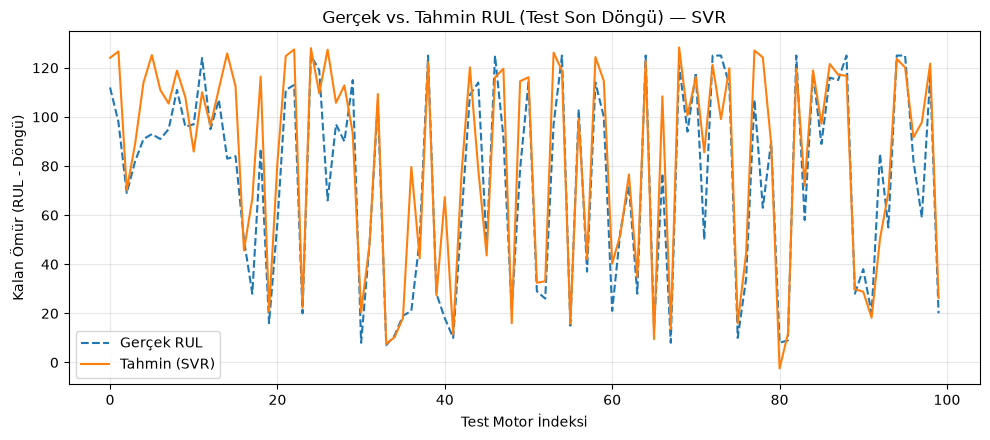

In [3]:
from sklearn.svm import SVR

svr_model = Pipeline(
    [("prep", preprocessor), ("model", SVR(kernel="rbf", C=10.0, epsilon=0.1))]
)
print("SVR eğitiliyor...")
_ = evaluate_model(svr_model, "SVR")

## 4.3 Random Forest Regressor
Doğrusal olmayan sensör bozulma örüntülerini yakalamak ve aşırı öğrenmeyi (overfitting) kontrol altında tutmak amacıyla derinliği sınırlandırılmış (`max_depth=12`, `min_samples_leaf=5`, `max_features="sqrt"`) 200 karar ağacından oluşan Random Forest modeli eğitilerek değerlendirilmiştir.

Random Forest Regressor eğitiliyor...
--- Random Forest Sonuçları ---
Train      -> RMSE: 12.75 | MAE: 9.12 | Doğruluk: %92.70
Test (Son) -> RMSE: 18.22 | MAE: 12.99 | R2: %79.33 | Doğruluk: %89.61
Validation -> RMSE: 16.27 | MAE: 11.71 | R2: %84.78 | Doğruluk: %90.64
Ezberleme  -> Test - Train RMSE: +5.47 döngü (Hafif Fark (Kontrollü))


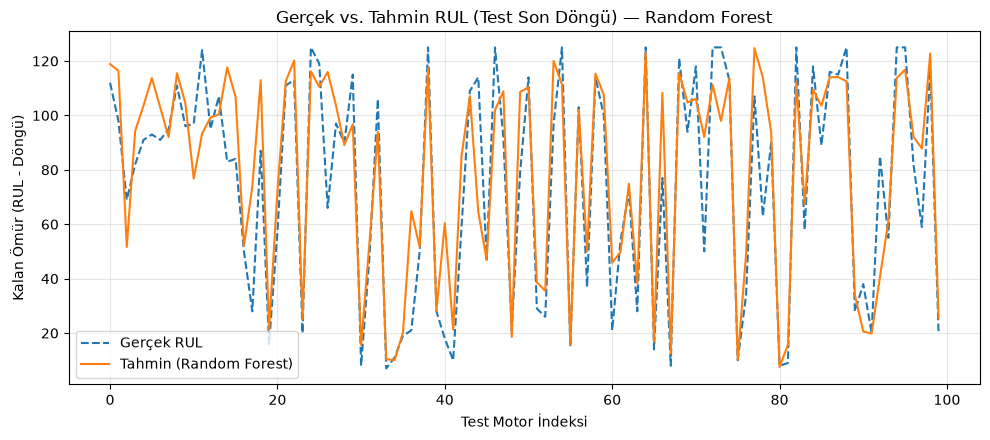

In [4]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("prep", preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

print("Random Forest Regressor eğitiliyor...")
rf_test_pred = evaluate_model(rf_model, "Random Forest")

## 4.5 Modellerin Karşılaştırılması

Modeller **Test (Son Döngü) RMSE** değerine göre sıralanmıştır (`Test RMSE` ne kadar düşükse hata o kadar düşüktür). En iyi çıkan model bir sonraki adımda **Validation (`val_fe.csv`)** üzerinden iyileştirilecektir.


NİHAİ MODEL KARŞILAŞTIRMASI (TEST SON DÖNGÜ)


,Model,Test RMSE,Test Doğruluk (%),Test R2 (%),Train RMSE,Val RMSE,Val Doğruluk (%),Ezberleme
0,Random Forest,18.220000,89.610000,79.330000,12.750000,16.270000,90.640000,Hafif Fark (Kontrollü)
1,SVR,19.360000,89.370000,76.670000,17.230000,16.930000,90.640000,Dengeli (Ezberleme yok)
2,Linear Regression,20.430000,87.000000,74.000000,21.030000,19.780000,87.230000,Dengeli (Ezberleme yok)


C:\Users\rafig\AppData\Local\Temp\ipykernel_22884\3938567553.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Test RMSE", y="Model", data=results_df, palette="viridis")


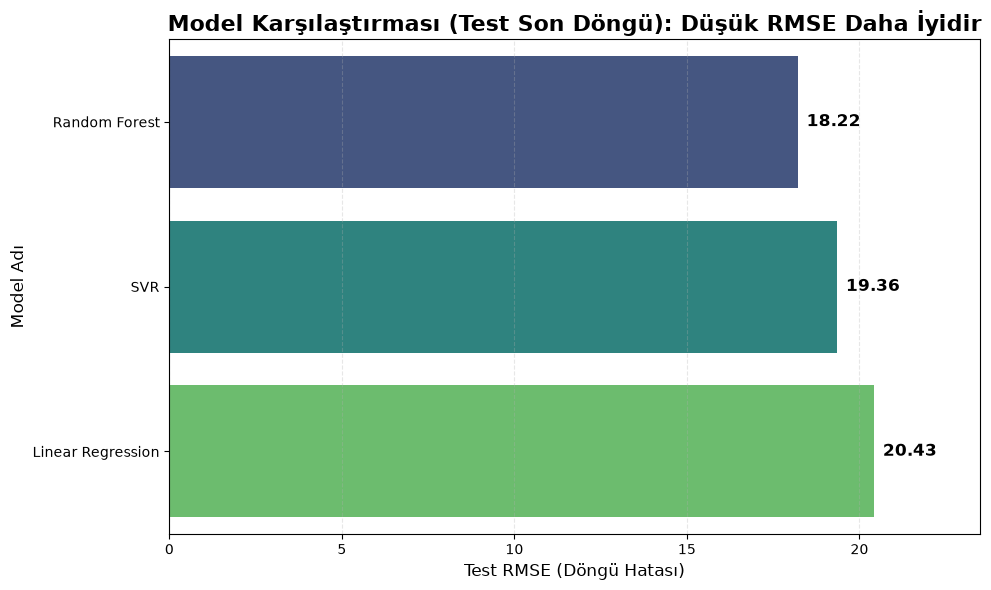

En İyi Model (Test): Random Forest


In [5]:
results_df = (
    pd.DataFrame(results_summary)
    .sort_values(by="Test RMSE")
    .reset_index(drop=True)
)

print("\nNİHAİ MODEL KARŞILAŞTIRMASI (TEST SON DÖNGÜ)")
display(
    results_df.style.background_gradient(cmap="Greens_r", subset=["Test RMSE"])
)

plt.figure(figsize=(10, 6))
sns.barplot(x="Test RMSE", y="Model", data=results_df, palette="viridis")
plt.title(
    "Model Karşılaştırması (Test Son Döngü): Düşük RMSE Daha İyidir",
    fontsize=16,
    fontweight="bold",
)
plt.xlabel("Test RMSE (Döngü Hatası)", fontsize=12)
plt.ylabel("Model Adı", fontsize=12)

for index, value in enumerate(results_df["Test RMSE"]):
  plt.text(
      value + 0.25, index, f"{value:.2f}", va="center", fontsize=12, fontweight="bold"
  )

plt.xlim(0, max(results_df["Test RMSE"]) * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"En İyi Model (Test): {results_df.iloc[0]['Model']}")